In [1]:
import glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, f1_score)

CLASS_NAMES = ["Normal", "Not Normal", "Lung Opacity"]     # labels 0, 1, 2
LEVELS = ["Routine", "Review soon", "Urgent"]              # levels 0, 1, 2
RES = Path("/kaggle/working/triage"); RES.mkdir(exist_ok=True)

def find(pattern):
    hits = glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)
    assert hits, f"'{pattern}' not found - attach the dataset that contains it (Add Input -> Your Datasets)"
    return hits[0]

va = pd.read_csv(find("val.csv"))
y, views = va["label"].values, va["view"].values
print("val images:", len(va), "| per class:", np.bincount(y))

def load_probs(name):
    p = np.load(find(f"{name}_val_probs.npy"))
    assert p.shape == (len(va), 3), p.shape
    return p

MODELS = {"densenet121_plain": load_probs("densenet121_plain"),
          "densenet121_viewbalanced": load_probs("densenet121_viewbalanced")}

for n, p in MODELS.items():       # must reproduce the training logs
    print(f"{n}: macro-AUROC {roc_auc_score(y, p, multi_class='ovr', average='macro'):.3f} | "
          f"macro-F1 {f1_score(y, p.argmax(1), average='macro'):.3f}")

val images: 4003 | per class: [1327 1774  902]
densenet121_plain: macro-AUROC 0.882 | macro-F1 0.693
densenet121_viewbalanced: macro-AUROC 0.862 | macro-F1 0.703


                         AUROC                                     PR-AUC  \
model        densenet121_plain densenet121_viewbalanced densenet121_plain   
class                                                                       
Lung Opacity             0.884                    0.858             0.692   
Normal                   0.950                    0.940             0.890   
Not Normal               0.812                    0.790             0.762   

                                       
model        densenet121_viewbalanced  
class                                  
Lung Opacity                    0.650  
Normal                          0.861  
Not Normal                      0.740  


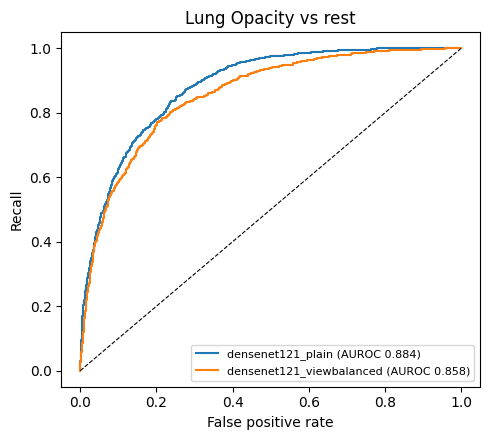

In [2]:
t_op = (y == 2).astype(int)
rows = []
for n, p in MODELS.items():
    for c, cname in enumerate(CLASS_NAMES):
        t = (y == c).astype(int)
        rows.append({"model": n, "class": cname,
                     "AUROC": roc_auc_score(t, p[:, c]),
                     "PR-AUC": average_precision_score(t, p[:, c])})
print(pd.DataFrame(rows).pivot(index="class", columns="model", values=["AUROC", "PR-AUC"]).round(3))

fig, ax = plt.subplots(figsize=(5, 4.5))
for n, p in MODELS.items():
    fpr, tpr, _ = roc_curve(t_op, p[:, 2])
    ax.plot(fpr, tpr, label=f"{n} (AUROC {roc_auc_score(t_op, p[:, 2]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("False positive rate"); ax.set_ylabel("Recall"); ax.set_title("Lung Opacity vs rest")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(RES / "roc_opacity.png", dpi=150); plt.show()

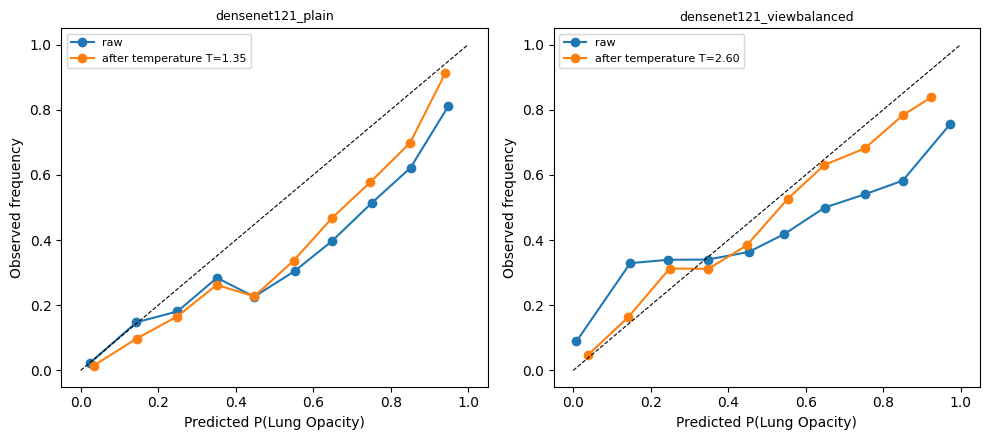

                             T  ECE_before  ECE_after
densenet121_plain         1.35       0.082      0.084
densenet121_viewbalanced  2.60       0.109      0.026


In [3]:
def ece_binary(prob, target, bins=10):
    """Expected calibration error: average gap between predicted and observed frequency."""
    edges, e = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (prob >= lo) & (prob < hi if hi < 1 else prob <= hi)
        if m.any(): e += m.mean() * abs(prob[m].mean() - target[m].mean())
    return e

def reliability_points(prob, target, bins=10):
    edges, xs, ys = np.linspace(0, 1, bins + 1), [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (prob >= lo) & (prob < hi if hi < 1 else prob <= hi)
        if m.sum() >= 20: xs.append(prob[m].mean()); ys.append(target[m].mean())
    return xs, ys

def apply_temperature(p, T):
    z = np.log(np.clip(p, 1e-8, 1)) / T
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def fit_temperature(p, y):
    grid = np.arange(0.5, 3.01, 0.05)
    nll = [-np.log(apply_temperature(p, T)[np.arange(len(y)), y] + 1e-12).mean() for T in grid]
    return float(grid[int(np.argmin(nll))])

calib, P = {}, {}
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for a, (n, p) in zip(ax, MODELS.items()):
    T = fit_temperature(p, y)
    P[n] = apply_temperature(p, T)
    calib[n] = {"T": T, "ECE_before": ece_binary(p[:, 2], t_op), "ECE_after": ece_binary(P[n][:, 2], t_op)}
    for pp, lab in [(p, "raw"), (P[n], f"after temperature T={T:.2f}")]:
        xs, ys = reliability_points(pp[:, 2], t_op)
        a.plot(xs, ys, marker="o", label=lab)
    a.plot([0, 1], [0, 1], "k--", lw=0.8)
    a.set_title(n, fontsize=9); a.set_xlabel("Predicted P(Lung Opacity)"); a.set_ylabel("Observed frequency")
    a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RES / "calibration.png", dpi=150); plt.show()
print(pd.DataFrame(calib).T.round(3))

In [4]:
def assign_triage(p, t_u, t_r):
    """Urgent if P(opacity) >= t_u; else Routine if P(normal) >= t_r; else Review soon."""
    level = np.full(len(p), 1)            # default: Review soon
    level[p[:, 0] >= t_r] = 0             # confidently normal -> Routine
    level[p[:, 2] >= t_u] = 2             # likely opacity -> Urgent (overrides)
    return level

def triage_metrics(y, level):
    opacity, abnormal = (y == 2), (y >= 1)
    urgent, routine = (level == 2), (level == 0)
    return {"urgent_recall": urgent[opacity].mean(),                 # opacity cases that reach Urgent
            "urgent_precision": opacity[urgent].mean() if urgent.any() else np.nan,
            "opacity_to_routine": routine[opacity].mean(),           # WORST error: sick case -> Routine
            "abnormal_to_routine": routine[abnormal].mean(),
            "routine_share": routine.mean(),                         # workload that can be deprioritised
            "urgent_share": urgent.mean()}

base = {n: triage_metrics(y, p.argmax(1)) for n, p in P.items()}     # naive rule: top class wins
print("Naive argmax rule:"); print(pd.DataFrame(base).round(3))

Naive argmax rule:
                     densenet121_plain  densenet121_viewbalanced
urgent_recall                    0.757                     0.561
urgent_precision                 0.551                     0.650
opacity_to_routine               0.049                     0.035
abnormal_to_routine              0.141                     0.104
routine_share                    0.396                     0.343
urgent_share                     0.310                     0.195


                     densenet121_plain  densenet121_viewbalanced
t_urgent                         0.400                     0.190
t_routine                        0.630                     0.530
urgent_recall                    0.802                     0.807
urgent_precision                 0.513                     0.499
opacity_to_routine               0.018                     0.020
abnormal_to_routine              0.076                     0.083
routine_share                    0.318                     0.313
urgent_share                     0.352                     0.364

 densenet121_plain
assigned level  Review soon  Routine  Urgent
true class                                  
Lung Opacity          0.181    0.018   0.802
Normal                0.179    0.806   0.016
Not Normal            0.520    0.106   0.374

 densenet121_viewbalanced
assigned level  Review soon  Routine  Urgent
true class                                  
Lung Opacity          0.173    0.020   0.807
Normal  

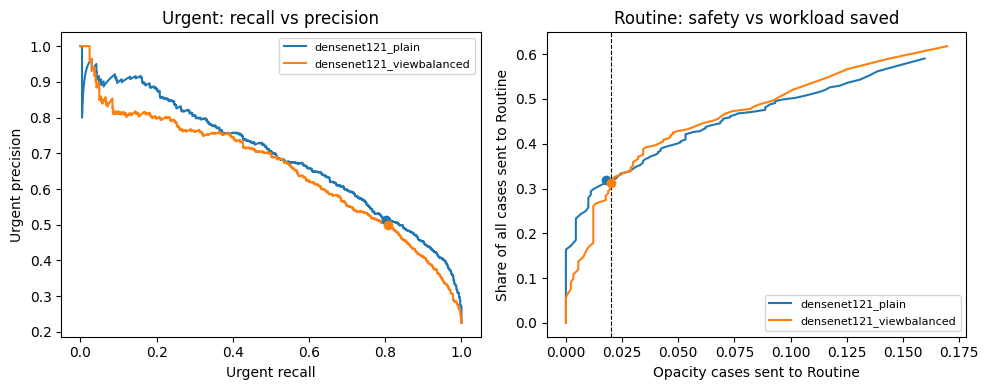

In [5]:
TARGET_URGENT_RECALL = 0.80       # policy choice: flag >= 80% of opacity cases as Urgent
MAX_OPACITY_TO_ROUTINE = 0.02     # policy choice: <= 2% of opacity cases may land in Routine
GRID = np.round(np.arange(0.01, 1.0, 0.01), 2)

def pick_thresholds(p, y):
    opacity = (y == 2)
    t_u = max(t for t in GRID if (p[opacity, 2] >= t).mean() >= TARGET_URGENT_RECALL)
    ok = [t for t in GRID
          if triage_metrics(y, assign_triage(p, t_u, t))["opacity_to_routine"] <= MAX_OPACITY_TO_ROUTINE]
    return float(t_u), float(min(ok))

chosen, rows = {}, {}
for n, p in P.items():
    t_u, t_r = pick_thresholds(p, y)
    chosen[n] = {"t_urgent": t_u, "t_routine": t_r}
    rows[n] = {"t_urgent": t_u, "t_routine": t_r, **triage_metrics(y, assign_triage(p, t_u, t_r))}
cmp_df = pd.DataFrame(rows).round(3)
print(cmp_df)

for n, p in P.items():
    lvl = assign_triage(p, chosen[n]["t_urgent"], chosen[n]["t_routine"])
    tab = pd.crosstab(pd.Series(y).map(dict(enumerate(CLASS_NAMES))).rename("true class"),
                      pd.Series(lvl).map(dict(enumerate(LEVELS))).rename("assigned level"),
                      normalize="index").round(3)
    print("\n", n); print(tab)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for n, p in P.items():
    prec, rec, _ = precision_recall_curve(t_op, p[:, 2])
    ax[0].plot(rec, prec, label=n)
    ax[0].scatter([rows[n]["urgent_recall"]], [rows[n]["urgent_precision"]], zorder=5)
    xs, ys = [], []
    for t in GRID:
        m = triage_metrics(y, assign_triage(p, chosen[n]["t_urgent"], t))
        xs.append(m["opacity_to_routine"]); ys.append(m["routine_share"])
    ax[1].plot(xs, ys, label=n)
    ax[1].scatter([rows[n]["opacity_to_routine"]], [rows[n]["routine_share"]], zorder=5)
ax[0].set_xlabel("Urgent recall"); ax[0].set_ylabel("Urgent precision"); ax[0].set_title("Urgent: recall vs precision")
ax[1].axvline(MAX_OPACITY_TO_ROUTINE, color="k", ls="--", lw=0.8)
ax[1].set_xlabel("Opacity cases sent to Routine"); ax[1].set_ylabel("Share of all cases sent to Routine")
ax[1].set_title("Routine: safety vs workload saved")
for a in ax: a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RES / "tradeoffs.png", dpi=150); plt.show()

In [6]:
for n, p in P.items():
    lvl = assign_triage(p, chosen[n]["t_urgent"], chosen[n]["t_routine"])
    for v in ["AP", "PA"]:
        k = views == v
        m = triage_metrics(y[k], lvl[k])
        print(f"{n:26s} {v}: urgent_recall {m['urgent_recall']:.3f} | "
              f"opacity_to_routine {m['opacity_to_routine']:.3f} | routine_share {m['routine_share']:.3f}")

rng = np.random.default_rng(42)
KEYS = ["urgent_recall", "urgent_precision", "opacity_to_routine", "abnormal_to_routine", "routine_share"]
for n, p in P.items():
    t_u, t_r = chosen[n]["t_urgent"], chosen[n]["t_routine"]
    boot = {k: [] for k in KEYS}
    for _ in range(1000):
        i = rng.integers(0, len(y), len(y))
        m = triage_metrics(y[i], assign_triage(p[i], t_u, t_r))
        for k in KEYS: boot[k].append(m[k])
    print("\n", n)
    for k in KEYS:
        lo, hi = np.nanpercentile(boot[k], [2.5, 97.5])
        print(f"   {k:22s} {rows[n][k]:.3f}   (95% CI {lo:.3f} - {hi:.3f})")

densenet121_plain          AP: urgent_recall 0.863 | opacity_to_routine 0.007 | routine_share 0.105
densenet121_plain          PA: urgent_recall 0.577 | opacity_to_routine 0.057 | routine_share 0.504
densenet121_viewbalanced   AP: urgent_recall 0.874 | opacity_to_routine 0.016 | routine_share 0.131
densenet121_viewbalanced   PA: urgent_recall 0.562 | opacity_to_routine 0.036 | routine_share 0.473

 densenet121_plain
   urgent_recall          0.802   (95% CI 0.775 - 0.826)
   urgent_precision       0.513   (95% CI 0.488 - 0.539)
   opacity_to_routine     0.018   (95% CI 0.010 - 0.027)
   abnormal_to_routine    0.076   (95% CI 0.066 - 0.086)
   routine_share          0.318   (95% CI 0.303 - 0.332)

 densenet121_viewbalanced
   urgent_recall          0.807   (95% CI 0.782 - 0.833)
   urgent_precision       0.499   (95% CI 0.473 - 0.524)
   opacity_to_routine     0.020   (95% CI 0.012 - 0.030)
   abnormal_to_routine    0.083   (95% CI 0.073 - 0.093)
   routine_share          0.313   (95% C

In [7]:
TARGETS = {"urgent_recall": TARGET_URGENT_RECALL, "max_opacity_to_routine": MAX_OPACITY_TO_ROUTINE}
config = {"policy": "Urgent if P(opacity) >= t_urgent; else Routine if P(normal) >= t_routine; else Review soon",
          "targets": TARGETS,
          "models": {n: {**chosen[n], "temperature": calib[n]["T"]} for n in MODELS},
          "selected_on": "validation set; test set untouched"}
json.dump(config, open(RES / "triage_config.json", "w"), indent=2)
cmp_df.to_csv(RES / "triage_comparison.csv")
print(json.dumps(config, indent=2))

{
  "policy": "Urgent if P(opacity) >= t_urgent; else Routine if P(normal) >= t_routine; else Review soon",
  "targets": {
    "urgent_recall": 0.8,
    "max_opacity_to_routine": 0.02
  },
  "models": {
    "densenet121_plain": {
      "t_urgent": 0.4,
      "t_routine": 0.63,
      "temperature": 1.3500000000000008
    },
    "densenet121_viewbalanced": {
      "t_urgent": 0.19,
      "t_routine": 0.53,
      "temperature": 2.600000000000002
    }
  },
  "selected_on": "validation set; test set untouched"
}
